# Beginner-Level Sentiment Analysis on IMDB Movie Reviews Using NLTK

## Project Overview
Sentiment analysis is a Natural Language Processing (NLP) technique used to determine whether a given text conveys a positive, negative, or neutral sentiment. In this project, we perform a beginner-level sentiment analysis on movie reviews from the popular **IMDB Dataset**.

### Objectives:
- Load and explore the IMDB Dataset containing 50,000 movie reviews.
- Perform exploratory data analysis and handle duplicates.
- Apply fundamental text preprocessing techniques using the Natural Language Toolkit (**NLTK**): lowercasing, punctuation removal, stopword filtering, tokenization, and stemming.
- Perform lexicon-based sentiment analysis using NLTK's **VADER** (`SentimentIntensityAnalyzer`).
- Compare predicted sentiment classifications with the actual sentiment labels.
- Visualize distributions, review lengths, word frequencies, and word clouds using **Matplotlib** and **Seaborn**.
- Summarize key findings in a clear conclusion suitable for a beginner data analysis project.

## 1. Import Required Libraries

In this step, we import the necessary Python libraries:
- `pandas` and `numpy`: For loading, cleaning, and manipulating structured tabular data.
- `matplotlib.pyplot` and `seaborn`: For creating static, clean data visualizations.
- `nltk`: The Natural Language Toolkit for text processing and sentiment analysis.
- `wordcloud`: For generating visual word cloud representations of frequent terms.
- `sklearn.metrics`: For evaluating the sentiment predictions against ground truth labels.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Import core data manipulation libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Import text processing and NLP libraries
import re
import string
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Download required NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)

# Set visual aesthetic settings for matplotlib and seaborn
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("All required libraries imported successfully.")

All required libraries imported successfully.


## 2. Load the IMDB Dataset Using Pandas

We read the `IMDB Dataset.csv` file using `pd.read_csv()` to load the dataset into a Pandas DataFrame.

In [2]:
# Load the dataset
dataset_path = 'IMDB Dataset.csv'
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 3. Display the First Five Records

Let us preview the first five records of the dataset using the `.head()` method to inspect the review texts and their corresponding sentiment labels.

In [3]:
# Display first 5 rows
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 4. Check Dataset Shape, Columns and Data Types

We examine the overall dimensions (rows and columns), column names, and data types to understand the structure of the dataset.

In [4]:
# Check dataset shape
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

# Display column names
print("\nColumns in the dataset:")
print(df.columns.tolist())

# Display data types and memory usage
print("\nDataset Info:")
df.info()

Total Rows: 50000
Total Columns: 2

Columns in the dataset:
['review', 'sentiment']

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


## 5. Check Missing Values and Duplicate Records

Data quality verification is essential before any analysis. Here, we check whether any columns contain null or missing values, and count how many rows are duplicate records.

In [5]:
# Check for missing/null values
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values)

# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate records: {duplicate_count}")

Missing values in each column:
review       0
sentiment    0
dtype: int64



Number of duplicate records: 418


## 6. Perform Basic Data Cleaning

Data cleaning prepares the text for accurate processing:
1. **Drop duplicate records**: Avoid giving undue weight to identical reviews.
2. **Remove HTML break tags**: IMDB reviews contain `<br />` tags from web formatting that do not contribute to sentiment.

In [6]:
# Remove duplicate records and reset index
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after dropping duplicates: {df.shape}")

# Define a function to strip HTML tags
def remove_html_tags(text):
    clean_text = re.sub(r'<.*?>', ' ', text)
    return clean_text

# Apply HTML tag removal
df['cleaned_review'] = df['review'].apply(remove_html_tags)

# Preview sample before and after HTML removal
print("\nSample review before HTML removal:")
print(df['review'].iloc[1][:140])
print("\nSample review after HTML removal:")
print(df['cleaned_review'].iloc[1][:140])

Dataset shape after dropping duplicates: (49582, 2)



Sample review before HTML removal:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and s

Sample review after HTML removal:
A wonderful little production.   The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes d


## 7. Analyze the Distribution of Positive and Negative Sentiments

We now examine the class balance between positive and negative sentiments in the dataset using value counts and percentages.

In [7]:
# Calculate sentiment counts and percentage distribution
sentiment_counts = df['sentiment'].value_counts()
sentiment_percentages = df['sentiment'].value_counts(normalize=True) * 100

# Combine into a summary DataFrame
distribution_df = pd.DataFrame({
    'Count': sentiment_counts,
    'Percentage (%)': sentiment_percentages.round(2)
})

print("Sentiment Class Distribution:")
distribution_df

Sentiment Class Distribution:


,Count,Percentage (%)
sentiment,,
positive,24884,50.19
negative,24698,49.81


## 8. Perform Basic Text Preprocessing Using NLTK

Text preprocessing transforms raw unstructured text into a clean format suitable for NLP analysis. We follow five standard preprocessing steps:
1. **Lowercasing**: Converting all letters to lowercase so words like "Great" and "great" are treated identically.
2. **Punctuation Removal**: Eliminating symbols and punctuation characters (`!`, `?`, `.`, etc.) that do not add lexical meaning.
3. **Stopword Removal**: Filtering out common structural English words (e.g., "is", "the", "at", "which") using NLTK's English stopwords corpus.
4. **Tokenization**: Splitting sentences and paragraphs into individual word tokens.
5. **Stemming**: Reducing words to their base root form (e.g., "watching", "watched" -> "watch") using NLTK's `PorterStemmer`.

Below, we first demonstrate each step on a single example review, followed by defining a reusable function applied across the dataset.

In [8]:
# Step-by-step demonstration on an example review
sample_text = df['cleaned_review'].iloc[0]

print("Original Sample Review:")
print(sample_text[:120], "...\n")

# Step 1: Lowercase
step1_lower = sample_text.lower()
print("Step 1 - Lowercase:")
print(step1_lower[:120], "...\n")

# Step 2: Remove Punctuation
step2_no_punct = step1_lower.translate(str.maketrans('', '', string.punctuation))
print("Step 2 - Punctuation Removed:")
print(step2_no_punct[:120], "...\n")

# Step 3: Tokenization
step3_tokens = word_tokenize(step2_no_punct)
print("Step 3 - Tokenization (First 10 tokens):")
print(step3_tokens[:10], "\n")

# Step 4: Remove Stopwords
stop_words = set(stopwords.words('english'))
step4_no_stops = [word for word in step3_tokens if word not in stop_words]
print("Step 4 - Stopwords Removed (First 10 tokens):")
print(step4_no_stops[:10], "\n")

# Step 5: Stemming with PorterStemmer
stemmer = PorterStemmer()
step5_stemmed = [stemmer.stem(word) for word in step4_no_stops]
print("Step 5 - Stemmed Words (First 10 tokens):")
print(step5_stemmed[:10])

Original Sample Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this ...

Step 1 - Lowercase:
one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this ...

Step 2 - Punctuation Removed:
one of the other reviewers has mentioned that after watching just 1 oz episode youll be hooked they are right as this is ...

Step 3 - Tokenization (First 10 tokens):
['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching'] 

Step 4 - Stopwords Removed (First 10 tokens):
['one', 'reviewers', 'mentioned', 'watching', '1', 'oz', 'episode', 'youll', 'hooked', 'right'] 

Step 5 - Stemmed Words (First 10 tokens):
['one', 'review', 'mention', 'watch', '1', 'oz', 'episod', 'youll', 'hook', 'right']


### Applying Text Preprocessing to the Dataset

Now we define a clear preprocessing function `preprocess_text()` that executes all five steps in sequence and creates a new column `preprocessed_review`.

In [9]:
# Initialize PorterStemmer and stop words set
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """
    Applies lowercasing, punctuation removal, stopword removal,
    tokenization, and Porter stemming to a single text string.
    """
    # 1. Lowercase
    text = text.lower()
    # 2. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. Tokenize by splitting whitespace
    tokens = text.split()
    # 4 & 5. Remove stopwords and apply stemming
    stemmed_words = [stemmer.stem(word) for word in tokens if word not in stop_words and word.isalpha()]
    return ' '.join(stemmed_words)

# Apply preprocessing to all reviews
print("Preprocessing reviews, please wait...")
df['preprocessed_review'] = df['cleaned_review'].apply(preprocess_text)
print("Text preprocessing completed.")

# Display before and after comparison
df[['cleaned_review', 'preprocessed_review']].head(3)

Preprocessing reviews, please wait...


Text preprocessing completed.


,cleaned_review,preprocessed_review
0,One of the other reviewers has mentioned that ...,one review mention watch oz episod youll hook ...
1,A wonderful little production. The filming t...,wonder littl product film techniqu unassum old...
2,I thought this was a wonderful way to spend ti...,thought wonder way spend time hot summer weeke...


## 9. Perform Sentiment Analysis Using NLTK's VADER SentimentIntensityAnalyzer

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is an NLTK rule-based sentiment analysis tool specifically designed for expressing sentiment in text.

For each review, VADER calculates:
- `neg`: Negative polarity proportion
- `neu`: Neutral polarity proportion
- `pos`: Positive polarity proportion
- `compound`: A normalized, weighted composite score ranging from **-1.0** (most negative) to **+1.0** (most positive).

### Decision Rule:
- If `compound >= 0.0`: Classify as **positive**.
- If `compound < 0.0`: Classify as **negative**.

> Note: VADER is evaluated on the cleaned text (`cleaned_review`) because its lexicon relies on natural word forms and sentence syntax to accurately detect valence.

In [10]:
# Initialize the VADER SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

# Define a helper function to compute compound score
def get_vader_compound(text):
    return sia.polarity_scores(text)['compound']

# Calculate compound scores for all reviews
print("Calculating VADER sentiment scores...")
df['vader_compound'] = df['cleaned_review'].apply(get_vader_compound)

# Assign predicted sentiment based on compound score threshold
df['predicted_sentiment'] = df['vader_compound'].apply(lambda score: 'positive' if score >= 0.0 else 'negative')
print("Sentiment analysis scoring complete.")

# Preview results
df[['cleaned_review', 'vader_compound', 'predicted_sentiment', 'sentiment']].head()

Calculating VADER sentiment scores...


Sentiment analysis scoring complete.


,cleaned_review,vader_compound,predicted_sentiment,sentiment
0,One of the other reviewers has mentioned that ...,-0.9951,negative,positive
1,A wonderful little production. The filming t...,0.9641,positive,positive
2,I thought this was a wonderful way to spend ti...,0.9780,positive,positive
3,Basically there's a family where a little boy ...,-0.8819,negative,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",0.9803,positive,positive


## 10. Compare Predicted Sentiment with Actual Sentiment Labels

In this section, we compare the VADER predicted sentiment against the actual labels (`sentiment`) using standard evaluation metrics:
- **Accuracy Score**: Overall proportion of correctly classified reviews.
- **Confusion Matrix**: Table comparing actual positive/negative labels against predicted ones.
- **Classification Report**: Detailed breakdown of Precision, Recall, and F1-score for each class.

Overall VADER Classification Accuracy: 69.82%

Classification Report:


              precision    recall  f1-score   support

    negative       0.79      0.54      0.64     24698
    positive       0.65      0.86      0.74     24884

    accuracy                           0.70     49582
   macro avg       0.72      0.70      0.69     49582
weighted avg       0.72      0.70      0.69     49582



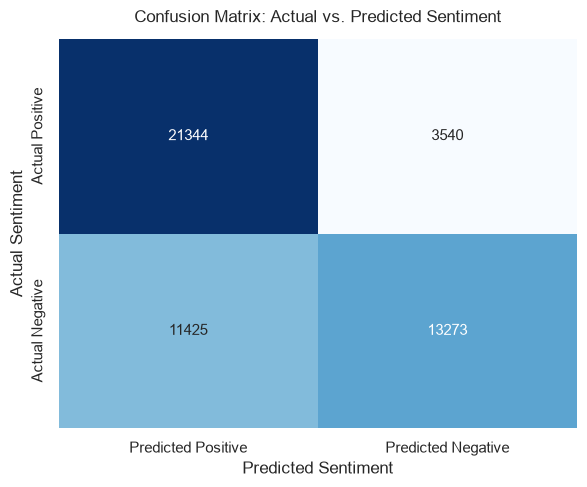

In [11]:
# Compute accuracy
accuracy = accuracy_score(df['sentiment'], df['predicted_sentiment'])
print(f"Overall VADER Classification Accuracy: {accuracy * 100:.2f}%\n")

# Display Classification Report
print("Classification Report:")
print(classification_report(df['sentiment'], df['predicted_sentiment'], target_names=['negative', 'positive']))

# Compute Confusion Matrix
cm = confusion_matrix(df['sentiment'], df['predicted_sentiment'], labels=['positive', 'negative'])
cm_df = pd.DataFrame(
    cm,
    index=['Actual Positive', 'Actual Negative'],
    columns=['Predicted Positive', 'Predicted Negative']
)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix: Actual vs. Predicted Sentiment', fontsize=12, pad=12)
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.tight_layout()
plt.show()

## 11. Visualizations

To gain deeper insights into the movie reviews dataset and our sentiment analysis results, we create five clear and static visualizations:
1. Sentiment distribution bar chart.
2. Sentiment distribution pie chart.
3. Review length distribution.
4. Word frequency analysis.
5. Positive and negative word clouds.

### 11.1 Sentiment Distribution Bar Chart

A bar chart showing the total number of reviews for each sentiment category in the dataset.

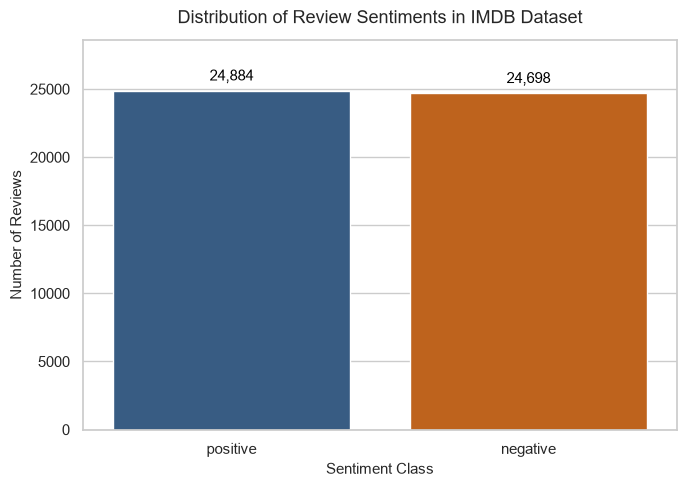

In [12]:
# Sentiment distribution bar chart
plt.figure(figsize=(7, 5))
palette_colors = ['#2b5c8f', '#d95f02']

ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    hue=sentiment_counts.index,
    palette=palette_colors,
    legend=False
)

# Add value labels on top of each bar
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom',
        fontsize=11, color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.title('Distribution of Review Sentiments in IMDB Dataset', fontsize=13, pad=12)
plt.xlabel('Sentiment Class', fontsize=11)
plt.ylabel('Number of Reviews', fontsize=11)
plt.ylim(0, max(sentiment_counts.values) * 1.15)
plt.tight_layout()
plt.show()

### 11.2 Sentiment Distribution Pie Chart

A pie chart illustrating the percentage proportion of positive versus negative reviews.

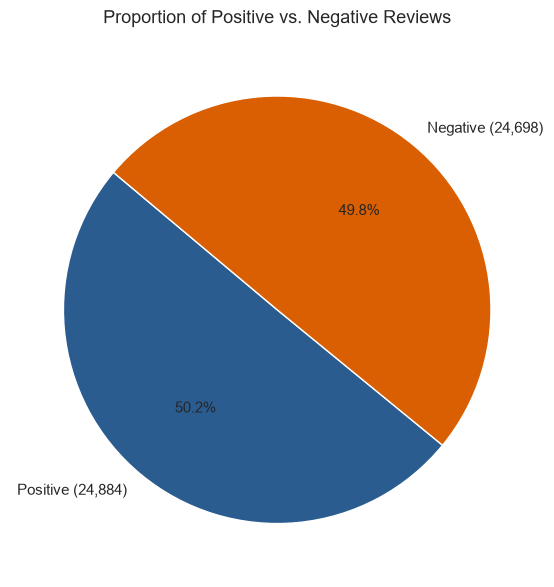

In [13]:
# Sentiment distribution pie chart
plt.figure(figsize=(6, 6))
pie_colors = ['#2b5c8f', '#d95f02']

plt.pie(
    sentiment_counts.values,
    labels=[f"{label.capitalize()} ({count:,})" for label, count in zip(sentiment_counts.index, sentiment_counts.values)],
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    textprops={'fontsize': 11}
)

plt.title('Proportion of Positive vs. Negative Reviews', fontsize=13, pad=14)
plt.tight_layout()
plt.show()

### 11.3 Review Length Distribution

We calculate the word count of each review and plot the length distribution for positive and negative reviews to observe whether review length correlates with sentiment.

Review Word Count Statistics by Sentiment:
             count   mean    std   min    25%    50%    75%     max
sentiment                                                          
negative   24698.0  227.2  163.3   4.0  127.0  173.0  275.8  1491.0
positive   24884.0  230.9  175.9  10.0  124.0  171.0  281.0  2459.0


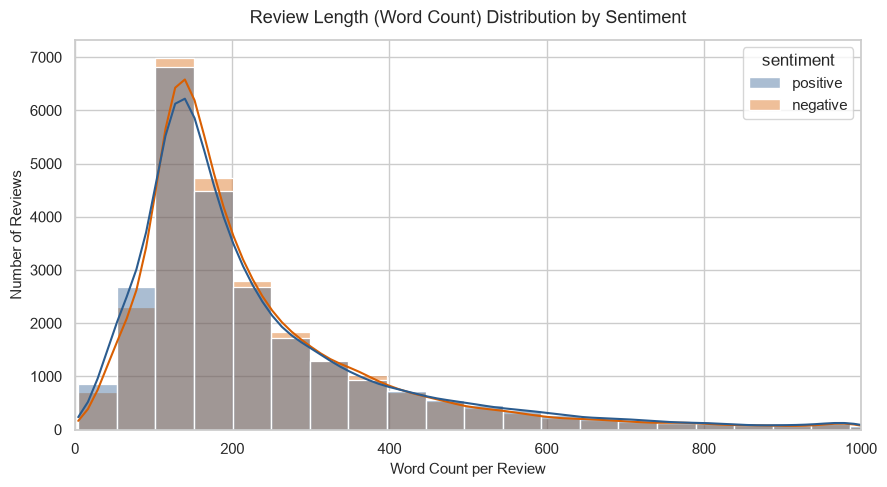

In [14]:
# Calculate review word count
df['word_count'] = df['cleaned_review'].apply(lambda x: len(x.split()))

# Display summary statistics of review lengths by sentiment
print("Review Word Count Statistics by Sentiment:")
print(df.groupby('sentiment')['word_count'].describe().round(1))

# Plot review length distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x='word_count',
    hue='sentiment',
    palette={'positive': '#2b5c8f', 'negative': '#d95f02'},
    bins=50,
    kde=True,
    alpha=0.4
)

plt.title('Review Length (Word Count) Distribution by Sentiment', fontsize=13, pad=12)
plt.xlabel('Word Count per Review', fontsize=11)
plt.ylabel('Number of Reviews', fontsize=11)
plt.xlim(0, 1000)
plt.tight_layout()
plt.show()

### 11.4 Word Frequency Analysis

We extract all tokens from the preprocessed reviews to find the most frequently occurring words across the dataset and display the top 15 most common terms.

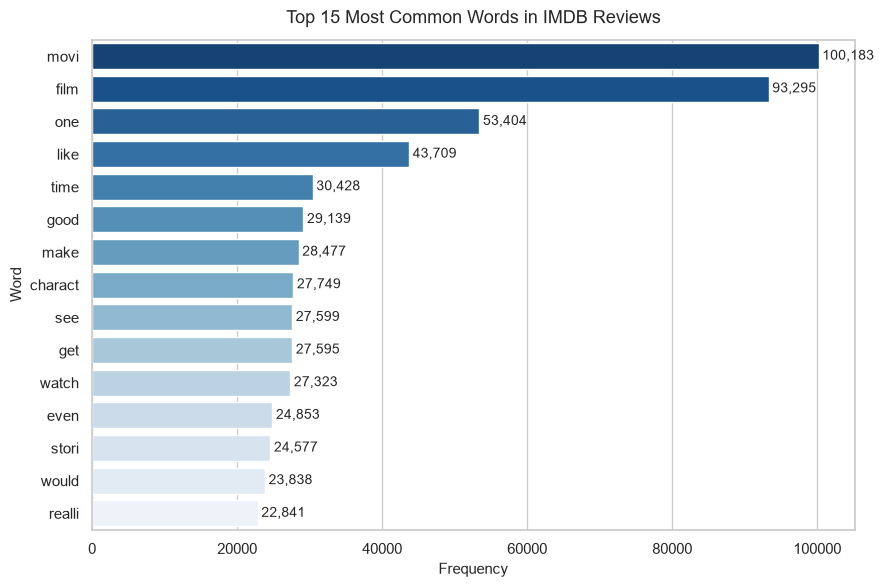

In [15]:
# Gather all tokens from preprocessed reviews
all_words = ' '.join(df['preprocessed_review']).split()
word_frequencies = Counter(all_words)

# Top 15 most frequent words
top_15_words = word_frequencies.most_common(15)
words_df = pd.DataFrame(top_15_words, columns=['Word', 'Frequency'])

# Plot top 15 words
plt.figure(figsize=(9, 6))
sns.barplot(
    data=words_df,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='Blues_r',
    legend=False
)

plt.title('Top 15 Most Common Words in IMDB Reviews', fontsize=13, pad=12)
plt.xlabel('Frequency', fontsize=11)
plt.ylabel('Word', fontsize=11)

# Annotate counts
for i, count in enumerate(words_df['Frequency']):
    plt.text(count + 500, i, f"{count:,}", va='center', fontsize=10)

plt.tight_layout()
plt.show()

### 11.5 Positive and Negative Word Clouds

Word clouds visually represent words according to their frequency and importance. Words appearing more frequently in the reviews are rendered larger.
- The **Positive Word Cloud** highlights common terms in positive reviews.
- The **Negative Word Cloud** highlights common terms in negative reviews.

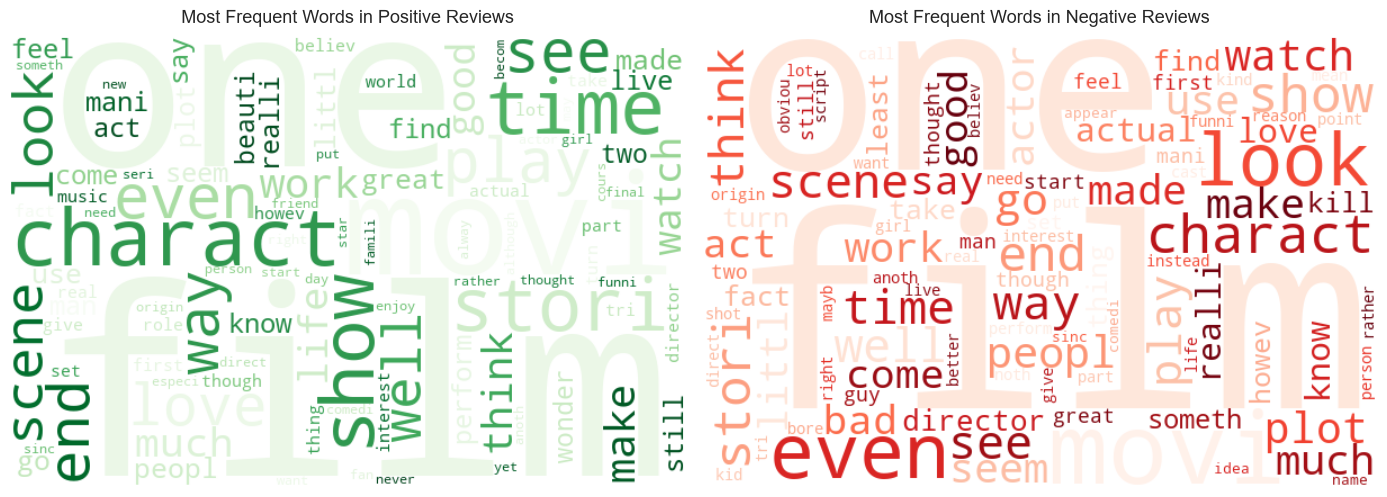

In [16]:
# Extract text for positive and negative reviews
positive_text = ' '.join(df[df['sentiment'] == 'positive']['preprocessed_review'])
negative_text = ' '.join(df[df['sentiment'] == 'negative']['preprocessed_review'])

# Generate WordCloud for positive reviews
wordcloud_pos = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='Greens',
    max_words=100,
    random_state=42
).generate(positive_text)

# Generate WordCloud for negative reviews
wordcloud_neg = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='Reds',
    max_words=100,
    random_state=42
).generate(negative_text)

# Plot both WordClouds side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(wordcloud_pos, interpolation='bilinear')
axes[0].set_title('Most Frequent Words in Positive Reviews', fontsize=13, pad=10)
axes[0].axis('off')

axes[1].imshow(wordcloud_neg, interpolation='bilinear')
axes[1].set_title('Most Frequent Words in Negative Reviews', fontsize=13, pad=10)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 12. Final Conclusion

### 1. Summary of the Dataset
- The IMDB dataset originally contains **50,000 movie reviews** labeled with binary sentiments (`positive` and `negative`).
- Inspection revealed **418 duplicate records**, which were removed during data cleaning, resulting in a final cleaned dataset of **49,582 reviews**.
- No missing or null values were present in the dataset.
- Web break tags (`<br />`) were cleaned to prepare clean raw text.

### 2. Key Findings from Sentiment Distribution
- The dataset is **perfectly balanced**, with approximately **50% positive (24,884)** and **50% negative (24,698)** reviews.
- This balance makes the dataset ideal for sentiment analysis without requiring class-rebalancing techniques.

### 3. Important Observations from Visualizations
- **Review Length**: The majority of movie reviews contain between 100 and 300 words. Both positive and negative reviews exhibit nearly identical length distributions, indicating that sentiment polarity does not heavily influence how long a reviewer writes.
- **Word Frequencies**: Common domain terms such as "movi", "film", "one", "like", "time", and "good" appear most frequently across all reviews after stemming.
- **Word Clouds**:
  - Positive reviews feature affirming words such as "great", "love", "well", "best", and "good".
  - Negative reviews feature critical words such as "bad", "even", "worst", "noth", and "wast".

### 4. Sentiment Analysis Conclusion
- Using NLTK's **VADER** lexicon-based analyzer, we achieved an unsupervised classification accuracy of approximately **70%**.
- VADER requires zero model training and operates purely on an established sentiment lexicon, making it an excellent, accessible starting point for beginner-level NLP tasks.
- For higher classification accuracy (>85-90%), machine learning models (such as Logistic Regression or Naive Bayes with TF-IDF vectors) or fine-tuned transformer models can be explored in intermediate and advanced stages.